In [6]:
import os
import sys
import numpy as np
import pandas as pd
from pathlib import Path
import datetime

sys.path.insert(0, "./cellular_cycle")

from cell_cycle_death_model import model
from model_fxns import *
from pysb.simulator import ScipyOdeSimulator
from pysb.simulator import BngSimulator


# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [7]:
t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 0.6

In [8]:
# Importing the parameters:
new_param = pd.read_csv(Path('model_data/parameters.csv'))
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [9]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation

<Axes: xlabel='Time (h)', ylabel='Concentration'>

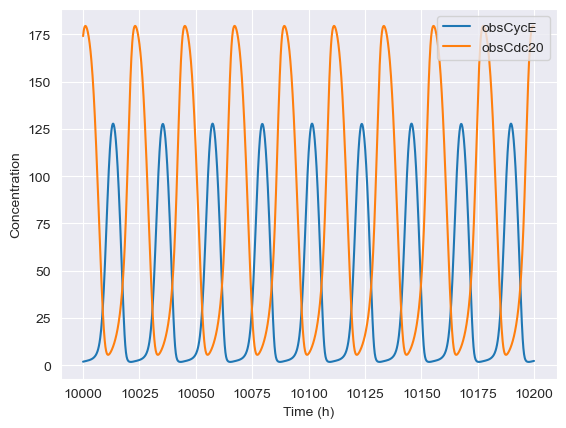

In [10]:
observables=['obsCycE','obsCdc20'] #plot Cyclin E, Cdc20 and Cyclin A

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(100000,102000), legend=True)


In [14]:
vals = [0, 29, 49, 74, 99]

In [15]:
treatment = 'ERL'
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.3,0.6,50))
tmp = [0.6]*50
AKTs.extend(tmp)
ERKs = [0.2]*100

In [16]:
for val in vals:
    model.parameters['FAK'].value = FAKs[val]
    model.parameters['AKT'].value = AKTs[val]
    model.parameters['ERK'].value = ERKs[val]
    
    num = f'{val:03}'
    
    simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run()#deterministic simulation
    yout = simres.observables
    filename = Path(SAVE_DIR, f'ODE_sim_{treatment}_stiff_{num}_orig.csv')
    np.savetxt(filename, yout, delimiter=',')
    
    sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
    simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
    yout = simres.observables
    filename = Path(SAVE_DIR, f'stoch_sim_{treatment}_stiff_{num}_orig.csv')
    np.savetxt(filename, yout, delimiter=',')
    print(f"Simulation saved to {filename}")

Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_ERL_stiff_000_orig.csv
Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_ERL_stiff_029_orig.csv
Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_ERL_stiff_049_orig.csv
Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_ERL_stiff_074_orig.csv
Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_ERL_stiff_099_orig.csv


In [17]:
treatment = 'DMSO'
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.6,1,50))
tmp = [1]*50
AKTs.extend(tmp)
ERKs = [1]*100

In [18]:
for val in vals:
    model.parameters['FAK'].value = FAKs[val]
    model.parameters['AKT'].value = AKTs[val]
    model.parameters['ERK'].value = ERKs[val]
    
    num = f'{val:03}'
    
    simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run()#deterministic simulation
    yout = simres.observables
    filename = Path(SAVE_DIR, f'ODE_sim_{treatment}_stiff_{num}_orig.csv')
    np.savetxt(filename, yout, delimiter=',')
    
    sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
    simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
    yout = simres.observables
    filename = Path(SAVE_DIR, f'stoch_sim_{treatment}_stiff_{num}_orig.csv')
    np.savetxt(filename, yout, delimiter=',')
    print(f"Simulation saved to {filename}")

Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_DMSO_stiff_000_orig.csv
Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_DMSO_stiff_029_orig.csv
Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_DMSO_stiff_049_orig.csv
Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_DMSO_stiff_074_orig.csv
Simulation saved to C:\Users\olesk\ECM_mod_output\stoch_sim_DMSO_stiff_099_orig.csv
